# [7.6] Automated Interpretability Agents (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter7_activation_to_language/exercises/part6_interpretability_agents/7.6_Automated_Interpretability_Agents_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter7_activation_to_language/exercises/part6_interpretability_agents/7.6_Automated_Interpretability_Agents_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A unit activates on two red circles. An explanation says “detects red.” Another says “detects circles.” A third says “detects red circles.” All three fit the examples. Which experiment should the interpreter run next?

By the end of this notebook, you will have shown that a bounded experiment-selection loop can distinguish these explanations for a planted image-property neuron, while a one-shot label and a fixed random explanation make measurable held-out simulation errors. You will inspect the agent's actual probe images, its changing hypothesis set and a causal input/feature edit with irrelevant-background controls.

This is the experimental structure of a MAIA/OpenMAIA-style agent, implemented locally with a transparent finite hypothesis controller. It is not a pretrained language or vision model, and the controller is not a small LLM. The native bridge section specifies how an instruction-tuned backend could propose the same structured actions; no backend is loaded or called here. This boundary keeps the causal question understandable instead of hiding it behind an API.

Prerequisites: [7.2] explanation/simulation, [6.3] feature dashboards and causal checks, and basic Python dictionaries. An articulate explanation is a hypothesis, not evidence. Our examples are public analytic fixtures; “held out” below means withheld from the controller's observation history, not unknown to a learner reading the complete notebook.

**Study edition:** the default examples are deterministic CPU teaching fixtures. No pretrained model is loaded, no network is used, and no trained-model benchmark or native qualification is claimed. Save a personal copy.

## Content & Learning Objectives

### 1️⃣ Explain a neuron with an experiment

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 2️⃣ A small tool interface with a real budget

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 3️⃣ Choose the experiment that separates hypotheses

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 4️⃣ Evaluate explanations rather than eloquence

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### ☆ Bonus

Predict a changed condition, inspect an anomaly, and plan the paper-to-model bridge.

## Setup code

In [ ]:
from pathlib import Path
import sys
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

chapter = "chapter7_activation_to_language"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part6_interpretability_agents.tests as tests

MAIN = __name__ == "__main__"
# NumPy arrays stay on CPU; float64 makes small analytic comparisons transparent.

# 1️⃣ Explain a neuron with an experiment

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

The controlled world has three binary properties: object color (red/blue), shape (circle/square) and background (plain/striped). We render actual tiny RGB images. An explicit sensor extracts the properties, and a planted unit computes $\operatorname{ReLU}(f_{red}+f_{circle}-1)$. Thus it responds only to red circles; the stripe sensor is irrelevant. The unit is synthetic on purpose: we know its ground truth and can independently score the explanation.

The controller is allowed to request images and activations. It does not use the target's source code when choosing an experiment. The learner can see that code to understand the oracle, but a clean controller benchmark would hide it and freeze the candidate family before collecting observations. Here the family is deliberately small: red, circle, conjunction and stripes. A unique survivor is identified only **within that family**. An outside-family target can still make it stop with a wrong survivor; the final play exposes exactly this failure and requires a separate counterexample audit.

Two positively activating examples cannot distinguish color from conjunction. A decisive counterfactual changes one property while keeping the others fixed. This is the scientific move the loop should learn to make. Looking at more identical positive examples can increase confidence without increasing identifiability.

### Exercise - implement `render_scene`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

The scene dictionary has exactly `color`, `shape`, `background`, with values red/blue, circle/square, plain/striped. Render a centered 3×3 object; our circle is a five-pixel cross, and the square fills all nine pixels. Stripes occupy the left border only, so they never overwrite the object. Return float pixels in `[0,1]`. Invalid categories must fail rather than being silently coerced into another example.

In [ ]:
def render_scene(scene):
    """Render a 7×7 RGB controlled object on an explicit background."""
    raise NotImplementedError()


tests.test_render_scene(render_scene)

<details>
<summary>Hint</summary>

Assign through the central view with a Boolean mask. The stripe is a separate border region, which gives a clean background control.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_render_scene passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def render_scene(scene):
    """Render a 7×7 RGB controlled object on an explicit background."""
    if set(scene)!={"color","shape","background"} or scene["color"] not in {"red","blue"} or scene["shape"] not in {"circle","square"} or scene["background"] not in {"plain","striped"}:
        raise ValueError("Invalid controlled scene")
    image=np.zeros((7,7,3),dtype=float)
    if scene["background"]=="striped":image[::2,0,:]=.5
    mask=np.ones((3,3),bool) if scene["shape"]=="square" else np.array([[0,1,0],[1,1,1],[0,1,0]],bool)
    color=np.array([1.,0.,0.]) if scene["color"]=="red" else np.array([0.,0.,1.])
    image[2:5,2:5][mask]=color
    return image
```
</details>

### Exercise - implement `image_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return three float indicators. Red is determined by the center pixel. Circle is identified by four absent corners of the central 3×3 region; require a visible center. Stripes are detected on the separate left border. This sensor is valid only for our renderer and must not be described as a general vision feature extractor. A natural-image bridge replaces it with a real cached neuron while keeping the experiment and scoring interfaces.

In [ ]:
def image_features(image):
    """Extract red, circle and stripe indicators from the controlled renderer."""
    raise NotImplementedError()


tests.test_image_features(image_features)

<details>
<summary>Hint</summary>

Inspect the object and the background in disjoint regions. A center-only sensor cannot distinguish these two shapes.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_image_features passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def image_features(image):
    """Extract red, circle and stripe indicators from the controlled renderer."""
    if np.asarray(image).shape!=(7,7,3) or not np.isfinite(image).all():
        raise ValueError("Expected finite 7×7 RGB image")
    center=image[3,3]
    corners=image[[2,2,4,4],[2,4,2,4]]
    return np.array([float(center[0]>center[2]),float(center.sum()>0 and np.all(corners==0)),float(np.any(image[:,0]>0))])
```
</details>

### Exercise - implement `hypothesis_predictions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`features` is `(examples,3)` in red/circle/stripe order. Support exactly red, circle, red-and-circle and stripes. Return one numeric prediction per example, and reject unknown names. The family is part of the experimental design: adding a hypothesis after seeing evaluation errors changes the benchmark. Natural-language explanations would need a separately frozen simulator or rubric rather than direct string matching.

In [ ]:
def hypothesis_predictions(name, features):
    """Predict unit activation from one frozen candidate explanation."""
    raise NotImplementedError()


tests.test_hypothesis_predictions(hypothesis_predictions)

<details>
<summary>Hint</summary>

A conjunction predicts zero on red squares and blue circles. Those counterexamples are more informative than a third red circle.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_hypothesis_predictions passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def hypothesis_predictions(name, features):
    """Predict unit activation from one frozen candidate explanation."""
    if name=="red":return features[:,0]
    if name=="circle":return features[:,1]
    if name=="red-and-circle":return features[:,0]*features[:,1]
    if name=="stripes":return features[:,2]
    raise ValueError("Unknown frozen hypothesis")
```
</details>

### Exercise - implement `simulation_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Require matching nonempty vectors and finite values; return their mean squared difference. Do not discard examples where an explanation is wrong, and do not fit a calibration slope using the evaluation labels. On binary predictions this is also the fraction of errors. A convincing text label with high simulation error remains a failed explanation for this task.

In [ ]:
def simulation_error(predicted, observed):
    """Mean squared activation error over every frozen evaluation example."""
    raise NotImplementedError()


tests.test_simulation_error(simulation_error)

<details>
<summary>Hint</summary>

The denominator is the full frozen cohort. A proper score must retain confident failures.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_simulation_error passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def simulation_error(predicted, observed):
    """Mean squared activation error over every frozen evaluation example."""
    p=np.asarray(predicted);y=np.asarray(observed)
    if p.shape!=y.shape or p.ndim!=1 or len(p)==0 or not np.isfinite(p).all() or not np.isfinite(y).all():
        raise ValueError("Finite aligned nonempty predictions required")
    return float(np.mean((p-y)**2))
```
</details>

In [ ]:
SCENES=[dict(color=c,shape=s,background=b) for c in ["red","blue"] for s in ["circle","square"] for b in ["plain","striped"]]
HYPOTHESES=["red","circle","red-and-circle","stripes"]
def target_unit(features):
    return np.maximum(features[0]+features[1]-1.,0.)
initial_scenes=[SCENES[0],SCENES[1]]
initial_history=[dict(scene=dict(scene),activation=float(target_unit(image_features(render_scene(scene))))) for scene in initial_scenes]

## The same evidence supports different explanations


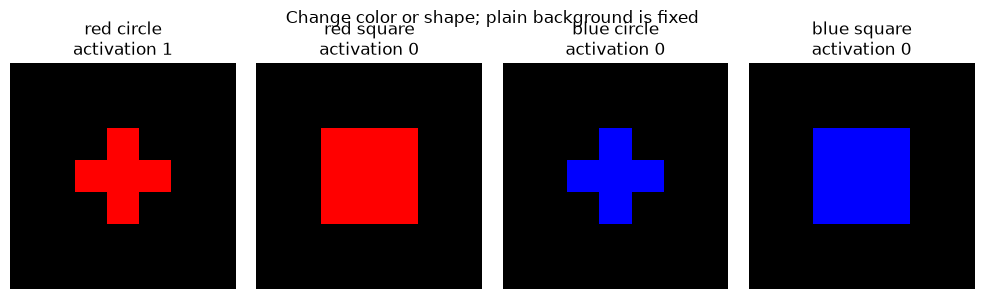

In [ ]:
fig,axes=plt.subplots(1,4,figsize=(10,3))
for ax,scene in zip(axes,[SCENES[0],SCENES[2],SCENES[4],SCENES[6]]):
    activation=target_unit(image_features(render_scene(scene)))
    ax.imshow(render_scene(scene));ax.set_title(f"{scene['color']} {scene['shape']}\nactivation {activation:g}");ax.axis("off")
fig.suptitle("Change color or shape; plain background is fixed");fig.tight_layout();plt.show()
display(pd.DataFrame(initial_history))

<details>
<summary>Help - how should I interpret this?</summary>

Red circles activate; red squares and blue circles do not. The controller initially sees only the two red-circle observations, so the counterfactual images are not yet in its history. The learner has now seen the answer and should record that exposure. These visible counterexamples are controls for a simple red-only or circle-only story.

</details>

## Summary of 1️⃣

An explanation must predict unseen-to-controller responses, not merely summarize activating examples. The planted sensor makes ground truth inspectable while keeping the controller observation boundary explicit.

# 2️⃣ A small tool interface with a real budget

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

MAIA-style systems reason through experiments, not just descriptions. Their tools can generate or edit inputs and inspect activations. That flexibility makes the execution boundary important: a model-generated tool call is proposed data, not authority to execute arbitrary code. Our deliberately finite tool interface has three actions: activation, ablate a specified sensor coordinate, and steer one coordinate by a bounded amount.

The scene vocabulary is finite. Actions have exact keys; there is no Python, shell, file path or network tool. The caller supplies the target function and owns the budget. A real service must also enforce authenticated principal, consent, isolation and logging outside the language model. Our schema validation is an educational contract, not a security sandbox.

We separate action validation from execution and keep observations as plain records. Failed or contradictory experiments cannot disappear from a trace just because they would make the explanation less tidy. The controller will only use activation probes for identification; feature edits are a later causal check. This prevents an intervention from being silently mixed into the observational simulator evaluation.

### Exercise - implement `validate_action`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

For activation require exactly `tool,scene`; for ablate add `feature`; for steer add `feature,amount`. Feature is a plain integer in 0..2. Amount is a finite plain number in `[-1,1]`. Reuse `render_scene` to validate categories, not to run a target. Reject extra keys such as code, path or command. Return a copied dictionary, including a copied scene, so a caller cannot mutate the already validated record by changing the original scene later.

In [ ]:
def validate_action(action):
    """Validate a finite activation/ablation/steering action without execution."""
    raise NotImplementedError()


tests.test_validate_action(validate_action)

<details>
<summary>Hint</summary>

Validate the exact key set for the selected tool. Rejecting a key is different from ignoring it and executing the rest.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_validate_action passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def validate_action(action):
    """Validate a finite activation/ablation/steering action without execution."""
    if not isinstance(action,dict) or action.get("tool") not in {"activation","ablate","steer"}:
        raise ValueError("Unknown tool")
    expected={"tool","scene"}|({"feature"} if action["tool"]!="activation" else set())|({"amount"} if action["tool"]=="steer" else set())
    if set(action)!=expected or not isinstance(action["scene"],dict):raise ValueError("Invalid tool schema")
    render_scene(action["scene"])
    if "feature" in action and (type(action["feature"]) is not int or not 0<=action["feature"]<3):raise ValueError("Invalid feature")
    if "amount" in action and (type(action["amount"]) not in (int,float) or not np.isfinite(action["amount"]) or not -1<=action["amount"]<=1):raise ValueError("Invalid steering dose")
    return {**action,"scene":dict(action["scene"])}
```
</details>

### Exercise - implement `execute_tool`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Render the scene, extract a new feature vector, then optionally set one feature to zero or add a bounded dose clipped to `[0,1]`. Return `action` and finite scalar `activation`; reject a nonfinite target result. Never mutate an input image/scene or return hidden target parameters. This analytic feature edit is not a natural-image edit, and its off-manifold interpretation is explicit.

In [ ]:
def execute_tool(action, target):
    """Execute one validated local tool call against a supplied target."""
    raise NotImplementedError()


tests.test_execute_tool(execute_tool)

<details>
<summary>Hint</summary>

The test target has independent known weights. Testing only the red-circle target would fail to distinguish the irrelevant stripe from an ignored edit.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_execute_tool passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def execute_tool(action, target):
    """Execute one validated local tool call against a supplied target."""
    action=validate_action(action);features=image_features(render_scene(action["scene"]))
    if action["tool"]=="ablate":features[action["feature"]]=0
    if action["tool"]=="steer":features[action["feature"]]=np.clip(features[action["feature"]]+action["amount"],0,1)
    value=float(target(features))
    if not np.isfinite(value):raise ValueError("Target returned a nonfinite activation")
    return dict(action=action,activation=value)
```
</details>

### Exercise - implement `parse_backend_action`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Parse exactly one JSON object, rejecting duplicate keys and nonstandard NaN/Infinity constants. Then call `validate_action`. This is the future backend seam: an instruction model may produce a structured proposal, but its text is never passed to `eval` or `exec`. Ordinary prose, Markdown fences and extra fields must fail clearly rather than being executed as a fallback.

In [ ]:
def parse_backend_action(text):
    """Parse JSON and validate an action; never evaluate model-produced code."""
    raise NotImplementedError()


tests.test_parse_backend_action(parse_backend_action)

<details>
<summary>Hint</summary>

A JSON parser can be configured to reject duplicate keys and nonfinite constants. Parsing is not authorization.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_parse_backend_action passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def parse_backend_action(text):
    """Parse JSON and validate an action; never evaluate model-produced code."""
    def pairs(items):
        out={}
        for key,value in items:
            if key in out:raise ValueError("Duplicate JSON key")
            out[key]=value
        return out
    def nonfinite(value):raise ValueError("Nonfinite JSON constant")
    try:action=json.loads(text,object_pairs_hook=pairs,parse_constant=nonfinite)
    except (TypeError,json.JSONDecodeError) as exc:raise ValueError("Expected one JSON action") from exc
    return validate_action(action)
```
</details>

## A causal edit has a matched irrelevant control


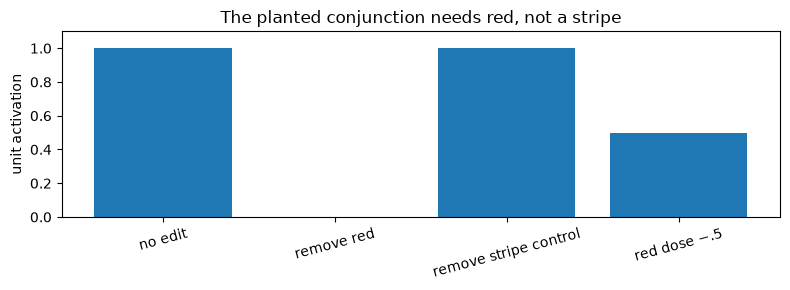

In [ ]:
scene=dict(color="red",shape="circle",background="striped")
actions=[dict(tool="activation",scene=scene),dict(tool="ablate",scene=scene,feature=0),dict(tool="ablate",scene=scene,feature=2),dict(tool="steer",scene=scene,feature=0,amount=-.5)]
observations=[execute_tool(a,target_unit)["activation"] for a in actions]
fig,ax=plt.subplots(figsize=(8,3));ax.bar(["no edit","remove red","remove stripe control","red dose −.5"],observations);ax.set(ylabel="unit activation",title="The planted conjunction needs red, not a stripe",ylim=(0,1.1));ax.tick_params(axis="x",rotation=15);fig.tight_layout();plt.show()

<details>
<summary>Help - how should I interpret this?</summary>

The irrelevant stripe edit leaves the unit unchanged, while removing red sets activation to zero. A half-strength red edit gives an intermediate response under this analytic ReLU unit. These are internal sensor interventions in the organism, not claims that a language model uses a named concept the same way.

</details>

## Summary of 2️⃣

Tool proposals need explicit schemas and caller-owned execution. The observation trace should contain what was actually run, and causal edits should remain distinct from ordinary simulator probes.

# 3️⃣ Choose the experiment that separates hypotheses

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

After each observation, keep every candidate whose predicted activation matches the observed value within a frozen tolerance. The next probe should be one on which the surviving candidates disagree. For binary candidate predictions, variance is maximized near an even split. This finite-family disagreement score is not a general Bayesian information-gain estimator, but its decision rule is transparent enough to audit.

Use the finite probe pool only. Do not repeat an already observed scene. Stable tie-breaking follows pool order. A budget counts **actual target calls**, not reasoning tokens. Stop when one candidate remains, the pool cannot distinguish the survivors, the budget is exhausted or observations contradict the family. The result must retain its reason; “budget exhausted” cannot be rewritten as “verified.”

The deterministic controller is a reference policy, not an LLM. It implements the experimental loop that an LLM-based MAIA agent also needs: propose, test, update, and explain. The later backend contract changes who proposes the experiment, while the tool budget and independent evaluation remain outside that proposer.

### Exercise - implement `consistent_hypotheses`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

History contains `{scene,activation}` records from unedited activation probes. Evaluate each candidate on all recorded scenes and keep it only if every absolute error is within tolerance. Return candidates in their original order. An empty history preserves all candidates; contradictory history can return an empty list. Do not select only the best-fitting candidate before the observations actually distinguish it.

In [ ]:
def consistent_hypotheses(candidates, history, tolerance=1e-9):
    """Retain candidates consistent with every activation observation."""
    raise NotImplementedError()


tests.test_consistent_hypotheses(consistent_hypotheses)

<details>
<summary>Hint</summary>

Consistency is the intersection of constraints from every observation, not a vote over examples.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_consistent_hypotheses passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def consistent_hypotheses(candidates, history, tolerance=1e-9):
    """Retain candidates consistent with every activation observation."""
    if tolerance<0:raise ValueError("Nonnegative tolerance required")
    if not history:return list(candidates)
    features=np.stack([image_features(render_scene(row["scene"])) for row in history])
    observed=np.array([row["activation"] for row in history])
    return [name for name in candidates if np.all(np.abs(hypothesis_predictions(name,features)-observed)<=tolerance)]
```
</details>

### Exercise - implement `probe_disagreement`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one variance per scene, averaging over hypotheses rather than examples. An empty candidate set has no valid disagreement score and should raise; one candidate gives all zeros. No target calls occur in this function. This separation lets you distinguish computational planning from consuming the experimental budget.

In [ ]:
def probe_disagreement(candidates, scenes):
    """Variance across candidate predictions for each proposed scene."""
    raise NotImplementedError()


tests.test_probe_disagreement(probe_disagreement)

<details>
<summary>Hint</summary>

Stack predictions into `(candidate,scene)` and reduce the candidate axis. The other reduction answers a different question.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_probe_disagreement passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def probe_disagreement(candidates, scenes):
    """Variance across candidate predictions for each proposed scene."""
    if not candidates:raise ValueError("No candidate family remains")
    features=np.stack([image_features(render_scene(scene)) for scene in scenes])
    predictions=np.stack([hypothesis_predictions(name,features) for name in candidates])
    return predictions.var(axis=0)
```
</details>

### Exercise - implement `choose_probe`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Exclude exact scenes already present in history. Among the remaining scenes, choose the first maximum disagreement, but return None if all candidates predict the same response everywhere. Do not choose a famous positive just because it agrees with the current leading hypothesis. Copy the chosen scene so later records cannot alias the pool.

In [ ]:
def choose_probe(candidates, scenes, history):
    """Choose an unobserved maximally disagreeing scene, or return None."""
    raise NotImplementedError()


tests.test_choose_probe(choose_probe)

<details>
<summary>Hint</summary>

A pool with no separating probe cannot establish which survivor is correct. Preserve ambiguity instead of spending calls on redundant observations.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_choose_probe passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def choose_probe(candidates, scenes, history):
    """Choose an unobserved maximally disagreeing scene, or return None."""
    unseen=[scene for scene in scenes if not any(scene==row["scene"] for row in history)]
    if not unseen:return None
    scores=probe_disagreement(candidates,unseen)
    if scores.max()<=0:return None
    return dict(unseen[int(scores.argmax())])
```
</details>

### Exercise - implement `run_agent`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Start from copied initial observations, filter candidates, then request one informative activation probe per round. Return `history`, `rounds`, `remaining`, `explanation`, `reason` and `calls`. Reasons are identified, contradicted, indistinguishable or budget_exhausted. The initial provided observations do not consume this additional-call budget. Each round records candidates before/after and the actual scene/result. Empty candidates mean no explanation, not permission to invent a new family from evaluation data.

In [ ]:
def run_agent(target, candidates, scenes, initial_history, budget=2):
    """Bounded hypothesis–probe–observation loop with a retained trace."""
    raise NotImplementedError()


tests.test_run_agent(run_agent)

<details>
<summary>Hint</summary>

Put the call counter beside the actual tool invocation. A hypothesis eliminated by evidence should not return in a later round.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_run_agent passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def run_agent(target, candidates, scenes, initial_history, budget=2):
    """Bounded hypothesis–probe–observation loop with a retained trace."""
    if type(budget) is not int or budget<0:raise ValueError("Nonnegative integer budget required")
    history=[dict(scene=dict(row["scene"]),activation=float(row["activation"])) for row in initial_history]
    remaining=consistent_hypotheses(candidates,history);rounds=[];calls=0
    while len(remaining)>1 and calls<budget:
        scene=choose_probe(remaining,scenes,history)
        if scene is None:break
        before=list(remaining)
        observation=execute_tool(dict(tool="activation",scene=scene),target);calls+=1
        row=dict(scene=observation["action"]["scene"],activation=observation["activation"])
        history.append(row);remaining=consistent_hypotheses(remaining,history)
        rounds.append(dict(before=before,scene=dict(scene),activation=row["activation"],after=list(remaining)))
    reason="identified" if len(remaining)==1 else "contradicted" if not remaining else "budget_exhausted" if calls>=budget else "indistinguishable"
    return dict(history=history,rounds=rounds,remaining=remaining,explanation=remaining[0] if len(remaining)==1 else None,reason=reason,calls=calls)
```
</details>

## Read the agent trace


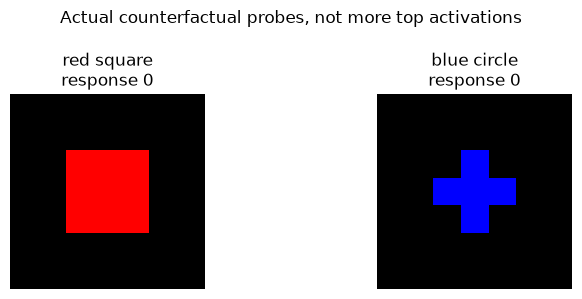

In [ ]:
agent=run_agent(target_unit,HYPOTHESES,SCENES,initial_history,budget=2)
display(pd.DataFrame(agent["rounds"]))
fig,axes=plt.subplots(1,max(1,len(agent["rounds"])),figsize=(8,3));axes=np.atleast_1d(axes)
for ax,row in zip(axes,agent["rounds"]):
    ax.imshow(render_scene(row["scene"]));ax.set_title(f"{row['scene']['color']} {row['scene']['shape']}\nresponse {row['activation']:g}");ax.axis("off")
fig.suptitle("Actual counterfactual probes, not more top activations");fig.tight_layout();plt.show()
print("result",agent["reason"],agent["explanation"],"additional calls",agent["calls"])
print("zero-budget control",run_agent(target_unit,HYPOTHESES,SCENES,initial_history,0)["reason"])

<details>
<summary>Help - how should I interpret this?</summary>

The initial plain-background red circle already rules out stripes. The next red-square and blue-circle probes eliminate red and circle respectively. The conjunction remains after two calls. The zero-budget control retains ambiguity. Exact probe order is fixed by the public pool order and the stable disagreement rule.

</details>

## Summary of 3️⃣

A decisive probe separates surviving explanations. The trace exposes whether the controller tested a counterfactual, repeated confirmations or simply ran out of budget.

# 4️⃣ Evaluate explanations rather than eloquence

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Freeze an evaluation cohort whose observations are withheld from the controller. An adaptive experiment consumes any examples it queries, so a scoring pool must not be reused for probe selection. The main comparison starts a fresh controller with **one red-circle plain-background observation**, restricts the probe pool to the four plain-background scenes, and evaluates only on the four striped-background scenes. Unlike the earlier demonstration history, this new controller has never received a striped-scene response. The learner has seen public reference examples, which is a separate exposure declaration.

The planner reads no evaluation labels, and the background is an irrelevant controlled change. This is a tiny fixed synthetic generalization check, not independent natural-model validation. Keep the complete four-item denominator even when a hypothesis fails. A natural-model experiment would need a broader independently constructed cohort and a frozen simulator/rubric, rather than assuming the four known binary factors exhaust the world.

The one-shot baseline chooses the first explanation consistent with the initial examples. A fixed random candidate uses a declared seed and no observation. Both must be scored on exactly the same four items as the iterative controller. A failed or ambiguous agent must count as an abstention; it cannot be silently removed from an average. Here we have one deterministic run, so the figure is descriptive and has no invented sampling interval.

### Exercise - implement `one_shot_explanation`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Use the same initial observations and candidate ordering as the iterative controller. Return the first survivor or None if all candidates contradict the evidence. This is a controlled one-shot baseline, not a claim about what a real LLM would say. Calling a second experiment inside this function would contaminate the budget comparison.

In [ ]:
def one_shot_explanation(candidates, history):
    """Choose the first consistent candidate without additional target calls."""
    raise NotImplementedError()


tests.test_one_shot_explanation(one_shot_explanation)

<details>
<summary>Hint</summary>

A consistent candidate is not necessarily uniquely identified. Keep the arbitrary frozen ordering visible.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_one_shot_explanation passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def one_shot_explanation(candidates, history):
    """Choose the first consistent candidate without additional target calls."""
    remaining=consistent_hypotheses(candidates,history)
    return remaining[0] if remaining else None
```
</details>

### Exercise - implement `intervention_effect`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return baseline minus edited activation. With `amount=None`, ablate the selected sensor; otherwise steer it by the provided bounded amount. Use the same scene in both calls and the validated tool interface. The signed effect distinguishes reducing a relevant feature from increasing it; taking an absolute value would hide that difference.

In [ ]:
def intervention_effect(scene, feature, target, amount=None):
    """Compare one feature edit against its own unedited activation."""
    raise NotImplementedError()


tests.test_intervention_effect(intervention_effect)

<details>
<summary>Hint</summary>

Match the baseline to the edited scene. Do not compare edited red circles with unedited blue squares.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_intervention_effect passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def intervention_effect(scene, feature, target, amount=None):
    """Compare one feature edit against its own unedited activation."""
    base=execute_tool(dict(tool="activation",scene=scene),target)["activation"]
    action=dict(tool="ablate",scene=scene,feature=feature) if amount is None else dict(tool="steer",scene=scene,feature=feature,amount=amount)
    return base-execute_tool(action,target)["activation"]
```
</details>

### Exercise - implement `score_explanations`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`explanations` maps method names to candidate names or None. Return a dictionary with shared `scenes`, `observed`, and `methods`, each method retaining its predicted list and MSE; abstentions retain `None` values and `abstained=True`. Do not invent predictions or drop an ambiguous method. Evaluation calls are outside the identification budget and must not be fed back to the controller.

In [ ]:
def score_explanations(explanations, scenes, target):
    """Retain per-item errors and explicit abstentions for a frozen cohort."""
    raise NotImplementedError()


tests.test_score_explanations(score_explanations)

<details>
<summary>Hint</summary>

Store every prediction beside its observation so aggregate errors remain auditable. A missing explanation is a missing result, not a perfect score.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_score_explanations passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>


<details><summary>Solution</summary>

```python
def score_explanations(explanations, scenes, target):
    """Retain per-item errors and explicit abstentions for a frozen cohort."""
    features=np.stack([image_features(render_scene(scene)) for scene in scenes])
    observed=np.array([float(target(f)) for f in features])
    methods={}
    for name,explanation in explanations.items():
        if explanation is None:methods[name]=dict(predicted=None,mse=None,abstained=True)
        else:
            predicted=hypothesis_predictions(explanation,features)
            methods[name]=dict(predicted=predicted.tolist(),mse=simulation_error(predicted,observed),abstained=False)
    return dict(scenes=[dict(scene) for scene in scenes],observed=observed.tolist(),methods=methods)
```
</details>

## Signature result — explanations on unqueried backgrounds


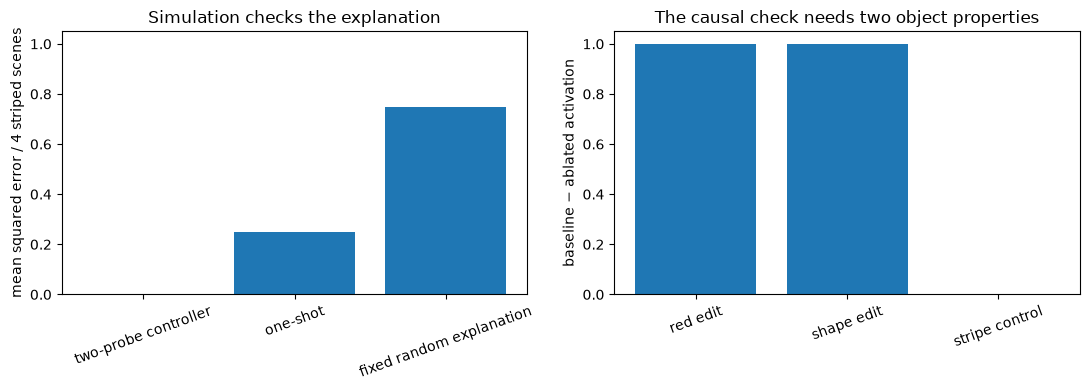

In [ ]:
probe_pool=[scene for scene in SCENES if scene["background"]=="plain"]
evaluation=[scene for scene in SCENES if scene["background"]=="striped"]
training_history=[dict(scene=SCENES[0],activation=1.)]
final_agent=run_agent(target_unit,HYPOTHESES,probe_pool,training_history,2)
one_shot=one_shot_explanation(HYPOTHESES,training_history)
random_name=HYPOTHESES[int(np.random.default_rng(0).integers(len(HYPOTHESES)))]
explanations={"two-probe controller":final_agent["explanation"],"one-shot":one_shot,"fixed random explanation":random_name}
report=score_explanations(explanations,evaluation,target_unit)
display(pd.DataFrame({"scene":[str(s) for s in evaluation],"observed":report["observed"],**{name:item["predicted"] for name,item in report["methods"].items()}}))
fig,axes=plt.subplots(1,2,figsize=(11,4));names=list(explanations)
axes[0].bar(names,[report["methods"][n]["mse"] for n in names]);axes[0].set(ylabel="mean squared error / 4 striped scenes",ylim=(0,1.05),title="Simulation checks the explanation");axes[0].tick_params(axis="x",rotation=20)
scene=dict(color="red",shape="circle",background="striped")
axes[1].bar(["red edit","shape edit","stripe control"],[intervention_effect(scene,j,target_unit) for j in range(3)]);axes[1].set(ylabel="baseline − ablated activation",title="The causal check needs two object properties");axes[1].tick_params(axis="x",rotation=20);fig.tight_layout();plt.show()
print("frozen explanations",explanations)
print("controller calls",final_agent["calls"],"reason",final_agent["reason"])
print("simulation errors",{n:d["mse"] for n,d in report["methods"].items()})

<details>
<summary>Help - how should I interpret this?</summary>

The identification pool has plain backgrounds and evaluation has striped backgrounds; no evaluation response enters the controller. The iterative policy identifies conjunction with MSE 0, the first-consistent one-shot label is red with MSE 0.25, and the fixed seed selects stripes with MSE 0.75. The paired causal check removes red or circle while the irrelevant stripe edit leaves the unit unchanged. The exact four-item score is a property of this planted target and candidate family, not a population estimate of automated interpretability quality.

</details>

## Interpreting the result

The agent gains information because it asks a discriminating question, not because it produces more text. The zero-budget and one-shot conditions isolate that advantage. The synthetic feature intervention also checks whether the explanation names the properties needed by this unit. Neither a clean trace nor a perfect four-item score makes a natural-model explanation accepted.

## Try it yourself

Change only the target from a conjunction to red OR circle. Predict whether the frozen-family loop will notice that none of its candidates is globally correct. It can identify a wrong survivor before querying a decisive counterexample: candidate-family uniqueness is weaker than mechanism identification. Freeze a blue-circle audit before running it, then compare the selected explanation with that audit response. Do not add the OR explanation after seeing evaluation errors and report the repaired score as held out. Separately change the budget to one and inspect whether ambiguity is retained.

In [ ]:
def changed_target(features):
    return float(max(features[0],features[1]))
play_history=[dict(scene=SCENES[0],activation=float(changed_target(image_features(render_scene(SCENES[0])))))]
play=run_agent(changed_target,HYPOTHESES,probe_pool,play_history,budget=3)
display(pd.DataFrame(play["rounds"]))
print("changed target",play["reason"],play["remaining"])
audit_scene=dict(color="blue",shape="circle",background="plain")
audit_features=image_features(render_scene(audit_scene))[None,:]
print("predeclared blue-circle audit",float(changed_target(audit_features[0])))
print("selected explanation predicts",None if play["explanation"] is None else float(hypothesis_predictions(play["explanation"],audit_features)[0]))
print("one-call baseline",run_agent(target_unit,HYPOTHESES,probe_pool,training_history,1)["reason"])

<details>
<summary>Expected output and anomaly</summary>

The changed-target loop stops after one probe with `identified red`. The predeclared blue-circle audit activates at 1 while red predicts 0. It has ruled out its competing candidates, not established a complete explanation family. Preserve this failure; a real agent needs separate disconfirming evaluation rather than its own stopping declaration as acceptance.

</details>

## Limitations

| Topic | Taught here | Not covered here |
| --- | --- | --- |
| MAIA | Actual image probes, explicit hypothesis/simulator, tool trace, disagreement policy, bounded target calls, one-shot/random controls and causal edits | Trained natural-image feature/neuron, free-form multimodal hypothesis generation, broad held-out simulator/human evaluation |
| OpenMAIA | Open local tool boundary and a JSON backend-action adapter; caller controls schema, budget and observation flow | A pinned local instruction/multimodal backend, installed tokenizer/chat template, model/tool revisions, resource qualification and native behavior |

The source OpenMAIA study uses much larger multimodal backbones than this finite controller. Do not call a small text-only stand-in a reproduction of its results. An instruction backend would receive an explicit observation summary and return one `tool` action in the schema above; the caller validates it, executes at most one approved local tool and appends the actual observation. No fallback executes arbitrary text. An actual host still needs principal/consent/privacy/approval gates and process isolation.

Before a native run, freeze target-model/neuron identity, data partition and exposure, candidate-generation policy, tool schema and image-generator revisions, maximum calls/tokens, stopping/abstention policy, simulator scoring and controls. No model budget or API call is authorized by this teaching notebook. The full trace should retain failed actions and negative results.

# ☆ Bonus

## Confirmation-bias challenge

Replace disagreement selection with “choose another predicted-positive scene.” Freeze that policy before observing its trace. Does a second red circle separate red from conjunction? Count unique discriminating observations rather than calls alone. Propose a background shift outside the three-property renderer and state which native evidence it would require.

## Further reading

- [MAIA project and paper](https://multimodal-interpretability.csail.mit.edu/maia/): a multimodal automated interpreter that designs experiments with tools.
- [OpenMAIA paper](https://openreview.net/pdf?id=KitDRi76It): an open-model MAIA-style stack; its backbone sizes and native tools are distinct from this synthetic controller.
- [MAIA official code](https://github.com/multimodal-interpretability/maia): inspect the actual experimental API, target model and evaluation rather than inferring them from an agent name.